# Sparse wafer-map metrology, part 2: baselines and realism
Part 1 built the model (the typical map plus 4 PCA shapes, fitted to a few readings by Bayesian
linear regression) and compared it with one baseline, rival A. Part 2 asks whether that result
holds up under harder and more realistic tests:

1. **Four baselines**, from no history at all to as much history as the model uses.
2. **A check on each measured reading**, so one bad reading can't bend the whole map.
3. **Three scores**, so the effect of the two suspect readings is visible instead of hidden.
4. **Lot-resampled error bars**, because only the 10 lots are independent, not the 88 wafers.
5. **Training only on earlier lots** (forward chaining), as a fab would have to.
6. **The routine 9 as actually read on etch day** by the second instrument.
7. **A second target**, silicon etch depth (step height minus the oxide mask).
8. **A wafer's position in its lot** as extra information.

**To run:** in Colab, Runtime → Run all. The data loads from this repository's `data/` folder
(or straight from GitHub). Runs in about a minute.

Data: Langer et al., BOSCH plasma-etching dataset, Zenodo 2025, doi:10.5281/zenodo.17122442 (CC BY 4.0).

## 0. Setup: data, the bad-reading screen and the model, unchanged from part 1
Copied from notebook 01 so that this notebook runs on its own. Notebook 01 explains each piece.

In [1]:
# Tools: numpy for arrays, pandas for tables, matplotlib for plots
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Where the data files are: the repository's data/ folder, or GitHub itself (e.g. in Colab)
DATA_URL = 'https://raw.githubusercontent.com/arifulRPI/sparse-wafer-metrology/main/data/'
def data_path(name):
    for folder in ['data', '../data', '.']:
        if os.path.exists(os.path.join(folder, name)):
            return os.path.join(folder, name)
    return DATA_URL + name

# Where figures go: the repository's figures/ folder if we're inside it, else the current folder
FIG_DIR = next((d for d in ['figures', '../figures'] if os.path.isdir(d)), '.')

full = pd.read_csv(data_path('Si_Oxide_etch_89_points.csv'))  # 89 sites per wafer (Feb 2025, KLA Tencor P-17)
rout = pd.read_csv(data_path('Si_Oxide_etch_9_points.csv'))   # 9 routine sites per wafer (etch day, Veeco Dektak 8)
TARGET = 'stepheight'      # main target; silicon etch depth is repeated in section 8

In [2]:
# The wafer x site tables: one row per wafer, one column per site
full['site'] = list(zip(full.X // 1000, full.Y // 1000))          # site = (x, y) in mm
sites = sorted(full.site.unique(), key=lambda s: (-s[1], s[0]))    # fixed order: top row first
wafers = full[['experiment_key', 'lot_number', 'wafer_number']].drop_duplicates()
wafers = wafers.sort_values(['lot_number', 'wafer_number']).reset_index(drop=True)
def table(column):
    """88 x 89 array of one measured quantity (µm), rows in lot/wafer order."""
    T = full.pivot(index='experiment_key', columns='site', values=column)
    return T.loc[wafers.experiment_key, sites].to_numpy()
Y = table(TARGET)                                                  # step height
Ysi = table('si_etch')                                             # silicon etch depth (step height minus oxide)
lot = wafers.lot_number.to_numpy()
lots = np.unique(lot)
xy = np.array(sites, dtype=float)                                  # site coordinates (mm)
r = np.hypot(xy[:, 0], xy[:, 1])                                   # site radius (mm)
inner = r <= 76.5                                                  # 49 inner sites, 40 outer
r9 = rout[['loc_id', 'X', 'Y']].drop_duplicates()
routine = [sites.index((x // 1000, y // 1000)) for x, y in zip(r9.X, r9.Y)]   # the routine 9 on the grid
rout = rout.dropna(subset=['experiment_key'])                      # drop rows with no wafer label
print('table:', Y.shape, '| inner/outer sites:', inner.sum(), (~inner).sum(), '| routine sites:', len(routine))

table: (88, 89) | inner/outer sites: 49 40 | routine sites: 9


In [3]:
# The bad-reading screen (part 1, section 3): compare each reading with the median of its
# neighbours, after removing the wafer's level and the typical map. Used on training wafers only.
dist = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])  # site-to-site distances (mm)
nbrs = [np.where((dist[s] > 0) & (dist[s] < 28.5))[0] for s in range(89)]      # touching sites
same_ring = [np.argsort(np.where((np.abs(r - r[s]) <= 10) & (dist[s] > 0), dist[s], np.inf))[:2]
             for s in range(89)]                                                # replacement sites

def screen_scores(M, ref):
    """Score every reading in M; 'typical' is learned from the reference maps ref (training wafers)."""
    typical = np.median(ref - np.median(ref, axis=1, keepdims=True), axis=0)   # typical map shape
    def gap(A):
        dev = A - np.median(A, axis=1, keepdims=True) - typical                # each wafer's own deviation
        return np.stack([dev[:, s] - np.median(dev[:, nbrs[s]], axis=1) for s in range(89)], axis=1)
    g, g_ref = gap(M), gap(ref)
    centre = np.median(g_ref, axis=0)                                  # usual gap at each site
    spread = 1.4826 * np.median(np.abs(g_ref - centre), axis=0)        # MAD, scaled to match a std
    return (g - centre) / spread, g - centre                           # score, and size in µm

def screen(M, ref, threshold):
    """Flag and replace readings one at a time, worst first, until none exceed the threshold."""
    M = M.copy()
    flagged = []
    done = np.zeros(M.shape, bool)
    while True:
        z, size = screen_scores(M, ref)
        z[done] = 0                                                    # each reading is flagged at most once
        w, s = np.unravel_index(np.argmax(np.abs(z)), z.shape)        # the most unusual reading left
        if abs(z[w, s]) <= threshold:
            return M, flagged
        flagged.append((w, s, M[w, s], z[w, s], size[w, s]))
        M[w, s] = M[w, same_ring[s]].mean()                          # replace with two same-ring sites
        done[w, s] = True

THRESHOLD = 30
def suspects_of(M):
    """Where the screen flags a reading on all wafers: used only to decide what to score, never to fit."""
    return [(w, s) for w, s, *_ in screen(M, M, THRESHOLD)[1]]
suspect = suspects_of(Y)
for w, s in suspect:
    print('suspect reading: lot %d wafer %d, site %s' % (lot[w], wafers.wafer_number[w], sites[s]))

suspect reading: lot 6 wafer 7, site (-76, -38)
suspect reading: lot 3 wafer 2, site (95, -19)


In [4]:
# The model (part 1, section 5): depth = average map + level + b1*shape1 + ... + b4*shape4 + leftover
K = 4   # number of shapes, fixed before testing

def learn(M, K):
    """Learn everything the fit needs from training maps M (rows = wafers)."""
    level = M.mean(axis=1)                                  # each wafer's mean depth
    dev = M - level[:, None]
    avg = dev.mean(axis=0)                                  # average map (shape only)
    D = dev - avg
    Vt = np.linalg.svd(D, full_matrices=False)[2][:K]       # the K shapes
    b = D @ Vt.T                                            # how much of each shape every wafer has
    leftover = D - b @ Vt                                   # what the shapes miss
    return dict(avg=avg, shapes=Vt,
                prior_mean=np.r_[level.mean(), np.zeros(K)],              # typical level, zero shapes
                prior_var=np.r_[level.var(ddof=1), b.var(axis=0, ddof=1)],
                noise_var=np.mean(leftover**2, axis=0))                   # leftover spread at each site

def fit(m, idx, y_meas, prior_mean=None):
    """Posterior for (level, b1..bK) from readings y_meas (wafers x k) at sites idx; full maps + 90% ranges.
    prior_mean can be one row per wafer (section 9); by default it is the same for every wafer."""
    X_all = np.column_stack([np.ones(89), m['shapes'].T])      # 89 x (K+1): level column + shapes
    X = X_all[idx]                                             # rows for the measured sites
    w = 1 / m['noise_var'][idx]                                # trust each reading by its leftover spread
    P0 = 1 / m['prior_var']                                    # prior strength
    mu0 = m['prior_mean'][None, :] if prior_mean is None else prior_mean
    cov = np.linalg.inv(np.diag(P0) + X.T @ (w[:, None] * X))  # posterior spread of the coefficients
    rhs = (P0[None, :] * mu0).T + X.T @ (w[:, None] * (y_meas - m['avg'][idx]).T)
    coef = cov @ rhs                                           # posterior mean, one column per wafer
    pred = m['avg'][None, :] + (X_all @ coef).T                # predicted full maps
    sd = np.sqrt(np.sum((X_all @ cov) * X_all, axis=1) + m['noise_var'])   # prediction spread per site
    return pred, 1.645 * sd                                    # 90% range = pred ± 1.645 sd

# Rival A is the same fit with no shapes (K = 0): the typical map, shifted to match the readings.

## 1. Three ways to score a prediction
Every test hides all but k sites of a held-out wafer, predicts the hidden ones and compares them
with the truth. The error is the root-mean-square (RMS) over hidden sites, for the 49 inner sites
(within 76.5 mm) and the 40 outer sites (the edge) separately.

Two readings are 11.5 and 15.9 µm shallower than their neighbours (lot 3 wafer 2 and lot 6 wafer 7):
a measurement glitch or a real one-site defect, the data can't tell which. They matter in two ways.
As a hidden site, nothing can predict them. As a measured site, they can mislead the fit.

- **Score A** scores every hidden site, the two suspect readings included.
- **Score B** is part 1's score. It does not score the suspect sites, and it skips any layout that
  *measured* one.
- **Score C** is the main score from part 2 on. It does not score the suspect sites but keeps every
  layout, so a method has to cope with a suspect reading among its inputs.

In [5]:
# Which sites can be scored: False at the suspect readings (scores B and C)
def valid_mask(suspects, shape=Y.shape):
    v = np.ones(shape, bool)
    for w, s in suspects:
        v[w, s] = False
    return v
valid = valid_mask(suspect)

## 2. Four baselines
Ordered by how much history they use:
- **Rival B1, polynomial:** a smooth surface (level, two tilts and a bowl) fitted to the new wafer's
  readings alone. Its only history is the ridge strength, chosen on training wafers.
- **Rival B2, Gaussian process:** smooth interpolation of the new wafer's readings. History only sets
  its smoothness, by maximum likelihood on the training full maps.
- **Rival A:** the average training map, shifted to match the readings (part 1).
- **Rival A+GP:** rival A, plus a Gaussian process on what the average map leaves in the readings.
  It uses as much history as the model, but as a smoothness instead of shapes.

In [6]:
# Rival B1: level + two tilts + a bowl, fitted by ridge regression to the readings (the level is not shrunk)
xs, ys = xy[:, 0] / 100.0, xy[:, 1] / 100.0
PHI = np.column_stack([np.ones(89), xs, ys, xs**2 + ys**2])
LAMS = [1e-3, 1e-2, 1e-1, 1, 10, 100]

def poly_fit(idx, yk, lam):
    P = PHI[idx]
    D = np.diag([0, 1, 1, 1.0])
    c = np.linalg.solve(P.T @ P + lam * D, P.T @ yk.T)          # one column of coefficients per wafer
    return (PHI @ c).T

def choose_lam(Ytr, lays):
    """Ridge strength chosen on training wafers, with the same kind of layout as the test."""
    best = None
    for lam in LAMS:
        sse = 0
        for idx in lays:
            p = poly_fit(idx, Ytr[:, idx], lam)
            h = np.ones(89, bool); h[idx] = False
            sse += ((p - Ytr)[:, h] ** 2).sum()
        if best is None or sse < best[0]:
            best = (sse, lam)
    return best[1]

# Rival B2: a Gaussian process (squared-exponential correlation between sites)
D2 = dist ** 2
def gp_learn(Ytr):
    """Smoothness (length scale) and noise share chosen by maximum likelihood on training full maps."""
    Z = Ytr - Ytr.mean(axis=1, keepdims=True)
    N = len(Z)
    best = None
    for ell in [20, 30, 40, 60, 80, 100, 130, 160, 200, 260]:            # length scale (mm)
        Rm = np.exp(-D2 / (2 * ell ** 2))
        for ratio in [0.01, 0.03, 0.1, 0.3]:                             # noise relative to signal
            C = Rm + ratio ** 2 * np.eye(89)
            Ci = np.linalg.inv(C)
            logdet = np.linalg.slogdet(C)[1]
            s2 = np.einsum('wi,ij,wj->', Z, Ci, Z) / (N * 89)             # best overall variance
            ll = -0.5 * (N * 89 * np.log(s2) + N * logdet)                # log-likelihood (up to a constant)
            if best is None or ll > best[0]:
                best = (ll, ell, ratio)
    return dict(ell=best[1], ratio=best[2])

def gp_fit(g, idx, yk):
    """GP interpolation of the readings yk at sites idx, around a constant level fitted to them."""
    Rm = np.exp(-D2 / (2 * g['ell'] ** 2))
    C = Rm[np.ix_(idx, idx)] + g['ratio'] ** 2 * np.eye(len(idx))
    Ci = np.linalg.inv(C)
    one = np.ones(len(idx))
    mu = (yk @ Ci @ one) / (one @ Ci @ one)                              # constant level (generalised least squares)
    return mu[:, None] + (Rm[:, idx] @ Ci @ (yk - mu[:, None]).T).T

# Rival A+GP: the average map, plus a GP on the wafer's own deviation from it
def gpa_learn(Ytr, m_a):
    D = Ytr - Ytr.mean(axis=1, keepdims=True) - m_a['avg']             # training deviations from the average map
    return gp_learn(D) | {'avg': m_a['avg']}

def gpa_fit(g, idx, yk):
    return g['avg'][None, :] + gp_fit(g, idx, yk - g['avg'][idx][None, :])

## 3. A check on each measured reading
Part 1 found that a bad reading among the measured sites spreads across the predicted map.
The screen of section 0 can't catch it on a new wafer: it compares a reading with its neighbours,
and a new wafer has only a few readings. So each measured reading is predicted from the other k − 1
with the model, in units of its predicted spread. If the worst one is more than 6 spreads away, it is
dropped before the final fit, for every method. 6 is a loose first guess, set after seeing these lots;
part 3 sets the threshold on training lots only.

In [7]:
T_CHECK = 6.0

def loo_z(m, idx, yk):
    """How far each measured reading is from what the other readings predict, in predicted spreads."""
    z = np.zeros(yk.shape)
    for j in range(len(idx)):
        rest = np.delete(np.arange(len(idx)), j)
        pred, half = fit(m, idx[rest], yk[:, rest])
        z[:, j] = (yk[:, j] - pred[:, idx[j]]) / (half[idx[j]] / 1.645)
    return np.abs(z)

def keep_mask(m, idx, yk, use_check):
    """Which measured readings each wafer keeps: drops at most the single worst one."""
    keep = np.ones(yk.shape, bool)
    if use_check and len(idx) > 2:
        z = loo_z(m, idx, yk)
        j = np.argmax(z, axis=1)
        bad = z[np.arange(len(yk)), j] > T_CHECK
        keep[np.where(bad)[0], j[bad]] = False
    return keep

## 4. The test loop: every method, held-out lots, three scores
For each test lot: learn everything from the training lots (screen, average map, shapes, prior,
polynomial ridge strength, GP smoothness), then predict its wafers from 3, 5 or 9 random sites
(200 layouts each, the same layouts as part 1) or from the routine 9.
The same loop later runs with earlier lots only (section 6), with the second instrument's readings
(section 7) and with silicon etch depth (section 8).

In [8]:
METHODS = ['ours', 'rival A', 'rival A+GP', 'rival B1', 'rival B2']

def predict_all(models, idx, yk, keep):
    """Predictions from every method. Wafers with a dropped reading are refitted without it."""
    out = {meth: np.zeros((len(yk), 89)) for meth in METHODS}
    out['half'] = np.zeros((len(yk), 89))
    groups = {}
    for i, row in enumerate(keep):
        groups.setdefault(tuple(row), []).append(i)                    # wafers that kept the same readings
    for row, ws in groups.items():
        sel = idx[np.array(row)]
        y = yk[ws][:, np.array(row)]
        out['ours'][ws], half = fit(models['ours'], sel, y)
        out['half'][ws] = half[None, :]
        out['rival A'][ws] = fit(models['rival A'], sel, y)[0]
        out['rival A+GP'][ws] = gpa_fit(models['rival A+GP'], sel, y)
        out['rival B1'][ws] = poly_fit(sel, y, models['lam'])
        out['rival B2'][ws] = gp_fit(models['rival B2'], sel, y)
    return out

def run(Yall, valid_all, train_lots, test_lots, lays, use_check,
        readings=None, instrument=None, wafer_ok=None):
    """Test every method on every test lot. Returns per-lot sums of squared errors for each
    (layout, method, score, region), plus 90% coverage and the number of dropped readings.
      train_lots(L): the lots to learn from when lot L is tested
      readings:      the second instrument's readings at the routine 9 (section 7); default: read the map
      instrument(L): (offset, extra noise variance) of that instrument, learned from training lots
      wafer_ok:      which wafers can be tested (those with second-instrument readings, in section 7)"""
    acc = {}
    def add(key, li, sse, n):
        a = acc.setdefault(key, np.zeros((len(lots), 2)))
        a[li, 0] += sse
        a[li, 1] += n
    for L in test_lots:
        li = list(lots).index(L)
        tr = np.isin(lot, train_lots(L))
        assert L not in set(lot[tr])                                   # leakage check: test lot never trains
        te = np.where(lot == L)[0]
        if wafer_ok is not None:
            te = te[wafer_ok[te]]
        if len(te) == 0:
            continue
        Ytr, _ = screen(Yall[tr], Yall[tr], THRESHOLD)                 # screen training wafers only
        models = {'ours': learn(Ytr, K), 'rival A': learn(Ytr, 0), 'rival B2': gp_learn(Ytr)}
        models['rival A+GP'] = gpa_learn(Ytr, models['rival A'])
        offset = 0.0
        if instrument is not None:
            offset, extra = instrument(L)
            for meth in ['ours', 'rival A']:                           # the instrument's own scatter
                models[meth]['noise_var'] = models[meth]['noise_var'].copy()
                models[meth]['noise_var'][routine] += extra
        truth, V = Yall[te], valid_all[te]                             # test wafers are never changed
        for lay, sets in lays.items():
            models['lam'] = choose_lam(Ytr, sets[:40])
            for idx in sets:
                yk = truth[:, idx] if readings is None else readings[te] - offset
                keep = keep_mask(models['ours'], idx, yk, use_check)
                P = predict_all(models, idx, yk, keep)
                hidden = np.ones(89, bool)
                hidden[idx] = False
                measured_ok = V[:, idx].all(axis=1)                    # no suspect reading among the inputs
                for meth in METHODS:
                    e2 = (P[meth] - truth) ** 2
                    for g, region in enumerate([inner, ~inner]):
                        hA = np.broadcast_to((hidden & region)[None, :], e2.shape)
                        hC = hA & V
                        hB = hC & measured_ok[:, None]
                        for score, h in [('A', hA), ('B', hB), ('C', hC)]:
                            add((lay, meth, score, g), li, e2[h].sum(), h.sum())
                for g, region in enumerate([inner, ~inner]):
                    hC = (hidden & region)[None, :] & V
                    inside = np.abs(P['ours'] - truth) <= P['half']   # true depth inside the 90% range?
                    add((lay, 'ours', 'cover', g), li, inside[hC].sum(), hC.sum())
                add((lay, 'ours', 'dropped', 0), li, (~keep).any(axis=1).sum(), len(te))
    return acc

def rmse(acc, lay, meth, score='C', region=None, lots_sel=None, per_lot=False):
    """RMS error over hidden sites. region: 0 = inner, 1 = outer, None = both."""
    regions = [0, 1] if region is None else [region]
    sse = sum(acc[(lay, meth, score, g)][:, 0] for g in regions)
    n = sum(acc[(lay, meth, score, g)][:, 1] for g in regions)
    if lots_sel is not None:
        keep = np.isin(lots, lots_sel)
        sse, n = sse[keep], n[keep]
    if per_lot:
        return np.sqrt(sse / np.maximum(n, 1))
    return float(np.sqrt(sse.sum() / n.sum()))

# The same random layouts as part 1 (same seed, same order)
ks = list(range(3, 14))
rng = np.random.default_rng(0)
layouts = {k: [rng.choice(89, k, replace=False) for _ in range(200)] for k in ks}
layouts['routine 9'] = [np.array(routine)]
LOLO = lambda L: lots[lots != L]                                       # leave one lot out
LAYS = {3: layouts[3], 5: layouts[5], 9: layouts[9], 'routine 9': layouts['routine 9']}

t0 = time.time()
R = {chk: run(Y, valid, LOLO, lots, LAYS, chk) for chk in [False, True]}
print('leave-one-lot-out, with and without the check: %.0f s' % (time.time() - t0))

leave-one-lot-out, with and without the check: 11 s


## 5. Results: which method wins, and what the suspect readings do
First the three scores at 5 random sites, with and without the check, for the model and rival A.

In [9]:
for chk in [False, True]:
    print('check %-3s' % ('on' if chk else 'off'), ' | '.join(
        'score %s: ours %.3f, rival A %.3f' % (sc, rmse(R[chk], 5, 'ours', sc), rmse(R[chk], 5, 'rival A', sc))
        for sc in 'ABC'))
for chk in [False, True]:
    po = rmse(R[chk], 5, 'ours', 'A', per_lot=True)
    pa = rmse(R[chk], 5, 'rival A', 'A', per_lot=True)
    print('score A, check %-3s: ours beats rival A in %d of 10 lots' % ('on' if chk else 'off', (po < pa).sum()))

# Share of the remaining score-A error that sits at the two suspect sites (check on)
A = R[True]
for meth in ['ours', 'rival A']:
    sa = sum(A[(5, meth, 'A', g)][:, 0].sum() for g in (0, 1))
    sc = sum(A[(5, meth, 'C', g)][:, 0].sum() for g in (0, 1))
    print('%-7s share of the score-A squared error at the 2 suspect sites: %.0f%%' % (meth, 100 * (sa - sc) / sa))

# How often the check fires: on layouts that measured a suspect reading, and on clean ones
def check_counts(k):
    caught = cases = alarms = clean = 0
    for L in lots:
        te = np.where(lot == L)[0]
        Ytr, _ = screen(Y[lot != L], Y[lot != L], THRESHOLD)
        m = learn(Ytr, K)
        for idx in layouts[k]:
            z = loo_z(m, idx, Y[te][:, idx])
            for i, w in enumerate(te):
                bad = [j for j, s in enumerate(idx) if (w, s) in suspect]
                if bad:
                    cases += 1
                    caught += int(np.argmax(z[i]) == bad[0] and z[i].max() > T_CHECK)
                else:
                    clean += 1
                    alarms += int(z[i].max() > T_CHECK)
    return caught, cases, alarms / clean
for k in [3, 5]:
    caught, cases, rate = check_counts(k)
    print('%d sites: the check caught the suspect reading %d of %d times | false alarms on clean wafers %.1f%%'
          % (k, caught, cases, 100 * rate))

check off score A: ours 0.298, rival A 0.274 | score B: ours 0.084, rival A 0.145 | score C: ours 0.196, rival A 0.157
check on  score A: ours 0.244, rival A 0.268 | score B: ours 0.093, rival A 0.146 | score C: ours 0.093, rival A 0.146
score A, check off: ours beats rival A in 8 of 10 lots
score A, check on : ours beats rival A in 10 of 10 lots
ours    share of the score-A squared error at the 2 suspect sites: 86%
rival A share of the score-A squared error at the 2 suspect sites: 70%


3 sites: the check caught the suspect reading 16 of 16 times | false alarms on clean wafers 2.5%


5 sites: the check caught the suspect reading 18 of 18 times | false alarms on clean wafers 3.8%


- **Score A is dominated by the two suspect readings.** They can't be predicted from other sites,
  whatever the method: 86% of the model's remaining score-A error sits at those two sites.
- **Without the check, the model loses to rival A overall on score A** (0.298 vs 0.274 µm), although it
  wins 8 of the 10 lots. In the two lots with a suspect reading, a measured suspect bends its whole map,
  more than it bends rival A's. Score C shows the same thing (0.196 vs 0.157 µm).
- **With the check, the model wins every lot on every score**, but on score A only by 9%.
- **The check has a small cost.** On layouts without a suspect reading (score B) the error rises from
  0.084 to 0.093 µm, because the check sometimes drops a good reading (3.8% of clean wafers at 5 sites,
  mostly in lot 1). Part 3 sets the threshold properly.

From here on, results use score C with the check on.

In [10]:
rows = []
for lay in [3, 5, 9, 'routine 9']:
    for meth in METHODS:
        rows.append({'readings': lay if lay == 'routine 9' else '%d random sites' % lay, 'method': meth,
                     'inner (µm)': rmse(A, lay, meth, 'C', 0), 'edge (µm)': rmse(A, lay, meth, 'C', 1)})
res = pd.DataFrame(rows)
print(res.pivot(index='method', columns='readings', values='edge (µm)').loc[METHODS].round(3).to_string())
print()
print(res.pivot(index='method', columns='readings', values='inner (µm)').loc[METHODS].round(3).to_string())

readings    3 random sites  5 random sites  9 random sites  routine 9
method                                                               
ours                 0.160           0.126           0.096      0.109
rival A              0.200           0.196           0.193      0.190
rival A+GP           0.195           0.173           0.153      0.155
rival B1             4.980           4.391           3.327      5.264
rival B2             5.143           5.058           4.962      5.690

readings    3 random sites  5 random sites  9 random sites  routine 9
method                                                               
ours                 0.074           0.053           0.033      0.021
rival A              0.094           0.086           0.079      0.075
rival A+GP           0.108           0.085           0.068      0.020
rival B1             2.888           2.063           1.831      0.436
rival B2             3.043           3.130           3.071      0.376


In [11]:
# Lots won, and lot-resampled 90% intervals for the gain of ours over each rival
for lay in [5, 9, 'routine 9']:
    for meth in ['rival A', 'rival A+GP', 'rival B1', 'rival B2']:
        po, pr = rmse(A, lay, 'ours', per_lot=True), rmse(A, lay, meth, per_lot=True)
        lost = lots[po >= pr].tolist()
        print('%-10s ours vs %-10s: wins %2d of 10 lots | per-lot gain %4.0f%% to %3.0f%%%s'
              % (lay, meth, (po < pr).sum(), 100 * (1 - po / pr).min(), 100 * (1 - po / pr).max(),
                 ' | loses lot %s' % lost if lost else ''))

# Resample the 10 lots with replacement, 5000 times, and recompute the gain each time
rng_boot = np.random.default_rng(0)
boot = {}
for lay in [5, 'routine 9']:
    for meth in ['rival A', 'rival A+GP']:
        for g in (0, 1):
            so, sr = A[(lay, 'ours', 'C', g)], A[(lay, meth, 'C', g)]
            gains = []
            for _ in range(5000):
                i = rng_boot.integers(0, 10, 10)
                gains.append(1 - np.sqrt(so[i, 0].sum() / so[i, 1].sum()) / np.sqrt(sr[i, 0].sum() / sr[i, 1].sum()))
            gain = 1 - np.sqrt(so[:, 0].sum() / so[:, 1].sum()) / np.sqrt(sr[:, 0].sum() / sr[:, 1].sum())
            boot[(lay, meth, g)] = (gain, *np.percentile(gains, [5, 95]))
            print('%-10s vs %-10s %-5s gain %3.0f%%  (90%% interval %3.0f%% to %3.0f%%)'
                  % (lay, meth, ['inner', 'edge'][g], 100 * gain, *(100 * np.array(boot[(lay, meth, g)][1:]))))

5          ours vs rival A   : wins 10 of 10 lots | per-lot gain   15% to  64%
5          ours vs rival A+GP: wins  9 of 10 lots | per-lot gain  -19% to  59% | loses lot [1]
5          ours vs rival B1  : wins 10 of 10 lots | per-lot gain   94% to  99%
5          ours vs rival B2  : wins 10 of 10 lots | per-lot gain   95% to  99%
9          ours vs rival A   : wins 10 of 10 lots | per-lot gain   24% to  71%
9          ours vs rival A+GP: wins 10 of 10 lots | per-lot gain    8% to  63%
9          ours vs rival B1  : wins 10 of 10 lots | per-lot gain   95% to  99%
9          ours vs rival B2  : wins 10 of 10 lots | per-lot gain   97% to  99%
routine 9  ours vs rival A   : wins 10 of 10 lots | per-lot gain   10% to  72%
routine 9  ours vs rival A+GP: wins  9 of 10 lots | per-lot gain  -15% to  62% | loses lot [1]
routine 9  ours vs rival B1  : wins 10 of 10 lots | per-lot gain   96% to  99%
routine 9  ours vs rival B2  : wins 10 of 10 lots | per-lot gain   96% to  99%
5          vs rival 

5          vs rival A+GP inner gain  38%  (90% interval  15% to  65%)


5          vs rival A+GP edge  gain  27%  (90% interval   9% to  47%)


routine 9  vs rival A    inner gain  72%  (90% interval  68% to  75%)
routine 9  vs rival A    edge  gain  43%  (90% interval  32% to  55%)
routine 9  vs rival A+GP inner gain  -4%  (90% interval -22% to  14%)
routine 9  vs rival A+GP edge  gain  30%  (90% interval  15% to  46%)


In [12]:
# The 90% prediction intervals: what share of hidden depths fall inside them? (should be about 90%)
for lay in [3, 5, 9, 'routine 9']:
    c = A[(lay, 'ours', 'cover', 0)] + A[(lay, 'ours', 'cover', 1)]
    print('%-10s coverage %.0f%%' % (lay, 100 * c[:, 0].sum() / c[:, 1].sum()))

3          coverage 86%
5          coverage 86%
9          coverage 86%
routine 9  coverage 89%


**What this shows.**
- The baselines that use the new wafer's readings alone (B1, B2) miss the edge by microns: no
  reading is near it, and nothing in the readings says the edge is 6–10 µm deeper. Some history is essential.
- Among the methods that use history, the model beats rival A in every lot and at every layout.
- Rival A+GP is the strong rival. The model beats it at the edge (27–30% lower), but with the routine 9
  the two tie on the inner sites, and A+GP wins lot 1, the lot whose left–right tilt is unlike the
  others (part 1, section 7b; figure 2 below).
- The earlier feasibility run reported 36–55% lower error than simpler methods. Its baselines weren't
  kept. The gain over rival A here (36–39% at 5 sites) falls in that range; the gain over the
  readings-only baselines is far larger.
- The 90% intervals are slightly too narrow (they hold 86% at 5 sites). Part 3 recalibrates them.

## 6. Training only on earlier lots (forward chaining)
A fab can only learn from wafers it has already etched. So lot L is predicted from lots 1 to L − 1,
starting at lot 4 (three lots of history). Compare with leave-one-lot-out on the same test lots.

In [13]:
FWD = lambda L: lots[lots < L]
F = run(Y, valid, FWD, lots[lots >= 4], {5: layouts[5], 'routine 9': layouts['routine 9']}, True)
later = lots[lots >= 4]
for lay in [5, 'routine 9']:
    for meth in ['ours', 'rival A']:
        f, l = rmse(F, lay, meth, lots_sel=later), rmse(A, lay, meth, lots_sel=later)
        print('%-10s %-8s earlier lots only %.3f | leave-one-lot-out, same lots %.3f | ratio %.2f'
              % (lay, meth, f, l, f / l))
    po = rmse(F, lay, 'ours', per_lot=True)[3:]
    pa = rmse(F, lay, 'rival A', per_lot=True)[3:]
    print('           ours beats rival A in %d of 7 lots' % (po < pa).sum())

5          ours     earlier lots only 0.072 | leave-one-lot-out, same lots 0.069 | ratio 1.04
5          rival A  earlier lots only 0.132 | leave-one-lot-out, same lots 0.128 | ratio 1.04
           ours beats rival A in 7 of 7 lots
routine 9  ours     earlier lots only 0.070 | leave-one-lot-out, same lots 0.070 | ratio 1.01
routine 9  rival A  earlier lots only 0.133 | leave-one-lot-out, same lots 0.129 | ratio 1.03
           ours beats rival A in 7 of 7 lots


Learning from earlier lots only costs about 4% at 5 sites and almost nothing with the routine 9.
Three lots of history are enough for the shapes.

## 7. The routine 9 as actually read on etch day
So far the routine 9 were read from the 89-site maps. In practice they come from the second
instrument, on etch day. Its site positions are rotated 180° relative to the maps (part 1, section 2),
and its readings differ from the maps by a constant offset. Both are undone here, with the offset learned from training
lots only. Of the 75 wafers it measured, 73 have a full map to score against.

In [14]:
# The second instrument's routine readings, arranged like the map table (sites turned 180°)
row_of = {k: i for i, k in enumerate(wafers.experiment_key)}
real = np.full((88, 9), np.nan)
for _, m in rout[rout.experiment_key.isin(set(wafers.experiment_key))].iterrows():
    j = sites.index((-m.X // 1000, -m.Y // 1000))
    real[row_of[m.experiment_key], routine.index(j)] = m[TARGET]
has = ~np.isnan(real).any(axis=1)
print('wafers with second-instrument readings and a full map:', has.sum(), '| lots:', sorted(set(lot[has].tolist())))

def instrument_noise(add_noise):
    def f(L):
        tr = has & (lot != L)                                          # training lots only
        diff = real[tr] - Y[tr][:, routine]
        return diff.mean(), (diff.var() if add_noise else 0.0)         # offset, and its scatter
    return f

REAL = {}
for add_noise in [False, True]:
    REAL[add_noise] = run(Y, valid, LOLO, lots, {'routine 9': layouts['routine 9']}, True,
                          readings=real, instrument=instrument_noise(add_noise), wafer_ok=has)
MAP_SAME = run(Y, valid, LOLO, lots, {'routine 9': layouts['routine 9']}, True, wafer_ok=has)
offset, extra = instrument_noise(True)(1)
print('learned with lot 1 held out: offset %.2f µm, scatter %.3f µm (RMS)' % (offset, np.sqrt(extra)))
for add_noise in [False, True]:
    Q = REAL[add_noise]
    d = Q[('routine 9', 'ours', 'dropped', 0)]
    po = rmse(Q, 'routine 9', 'ours', per_lot=True)
    pa = rmse(Q, 'routine 9', 'rival A', per_lot=True)
    tested = Q[('routine 9', 'ours', 'C', 0)][:, 1] > 0
    print('instrument scatter %-8s ours %.3f / %.3f | rival A %.3f / %.3f | flagged %d of %d wafers | ours wins %d of %d lots'
          % ('added:' if add_noise else 'ignored:',
             rmse(Q, 'routine 9', 'ours', 'C', 0), rmse(Q, 'routine 9', 'ours', 'C', 1),
             rmse(Q, 'routine 9', 'rival A', 'C', 0), rmse(Q, 'routine 9', 'rival A', 'C', 1),
             d[:, 0].sum(), d[:, 1].sum(), (po[tested] < pa[tested]).sum(), tested.sum()))
print('same wafers, routine 9 read from the map: ours %.3f / %.3f | rival A %.3f / %.3f'
      % (rmse(MAP_SAME, 'routine 9', 'ours', 'C', 0), rmse(MAP_SAME, 'routine 9', 'ours', 'C', 1),
         rmse(MAP_SAME, 'routine 9', 'rival A', 'C', 0), rmse(MAP_SAME, 'routine 9', 'rival A', 'C', 1)))

wafers with second-instrument readings and a full map: 73 | lots: [1, 2, 3, 4, 5, 6, 7, 9]


learned with lot 1 held out: offset -1.06 µm, scatter 0.048 µm (RMS)
instrument scatter ignored: ours 0.035 / 0.156 | rival A 0.078 / 0.200 | flagged 42 of 73 wafers | ours wins 6 of 8 lots
instrument scatter added:   ours 0.037 / 0.117 | rival A 0.070 / 0.204 | flagged 0 of 73 wafers | ours wins 8 of 8 lots
same wafers, routine 9 read from the map: ours 0.021 / 0.101 | rival A 0.078 / 0.193


The real readings carry the two instruments' 0.05 µm disagreement. If the model ignores it, it
trusts each reading too much: the check flags most wafers and the edge error rises. Adding the
instrument's scatter to the model's noise at the routine sites (learned from training lots) fixes both.
The model still recovers the edge from 9 real readings that never touch it.

## 8. A second target: silicon etch depth
Step height includes the oxide mask on top. Silicon etch depth subtracts it, and it is what process
engineers usually report. Same tests, same scores.

In [15]:
valid_si = valid_mask(suspects_of(Ysi))
SI = run(Ysi, valid_si, LOLO, lots, {5: layouts[5], 'routine 9': layouts['routine 9']}, True)
for lay in [5, 'routine 9']:
    po, pa = rmse(SI, lay, 'ours', per_lot=True), rmse(SI, lay, 'rival A', per_lot=True)
    print('%-10s ours %.3f / %.3f | rival A %.3f / %.3f | rival A+GP %.3f / %.3f | ours beats rival A in %d of 10 lots'
          % (lay, rmse(SI, lay, 'ours', 'C', 0), rmse(SI, lay, 'ours', 'C', 1),
             rmse(SI, lay, 'rival A', 'C', 0), rmse(SI, lay, 'rival A', 'C', 1),
             rmse(SI, lay, 'rival A+GP', 'C', 0), rmse(SI, lay, 'rival A+GP', 'C', 1), (po < pa).sum()))

5          ours 0.070 / 0.148 | rival A 0.097 / 0.213 | rival A+GP 0.099 / 0.187 | ours beats rival A in 10 of 10 lots
routine 9  ours 0.032 / 0.137 | rival A 0.073 / 0.219 | rival A+GP 0.048 / 0.184 | ours beats rival A in 10 of 10 lots


## 9. Does a wafer's position in its lot help?
Within a lot, the edge-minus-centre difference shrinks over the first few wafers. So a wafer's
position might predict its shape before anything is measured. Test: centre the prior on a straight-line
fit of the level and shape amounts against position (learned on training lots), then measure as before.

In [16]:
pos = wafers.wafer_number.to_numpy().astype(float)
def position_test(k):
    sse = {v: np.zeros(2) for v in ['plain prior', 'prior from position']}
    n = np.zeros(2)
    for L in lots:
        tr, te = lot != L, np.where(lot == L)[0]
        Ytr, _ = screen(Y[tr], Y[tr], THRESHOLD)
        m = learn(Ytr, K)
        level = Ytr.mean(axis=1)
        coefs = np.column_stack([level, (Ytr - level[:, None] - m['avg']) @ m['shapes'].T])  # each training wafer's level and shapes
        Xp = np.column_stack([np.ones(len(Y)), pos])
        B = np.linalg.lstsq(Xp[tr], coefs, rcond=None)[0]                                  # straight line in position
        mp = dict(m, prior_var=(coefs - Xp[tr] @ B).var(axis=0, ddof=2))                    # what position leaves unexplained
        mu_pos = Xp[te] @ B
        for idx in ([np.array([], int)] if k == 0 else layouts[k]):
            yk = Y[te][:, idx]
            keep = keep_mask(m, idx, yk, k > 0)
            hidden = np.ones(89, bool); hidden[idx] = False
            preds = {'plain prior': np.zeros((len(te), 89)), 'prior from position': np.zeros((len(te), 89))}
            groups = {}
            for i, row in enumerate(keep):
                groups.setdefault(tuple(row), []).append(i)                                 # wafers that kept the same readings
            for row, ws in groups.items():
                sel, y = idx[np.array(row, bool)], yk[ws][:, np.array(row, bool)]
                preds['plain prior'][ws] = fit(m, sel, y)[0]
                preds['prior from position'][ws] = fit(mp, sel, y, prior_mean=mu_pos[ws])[0]
            for g, region in enumerate([inner, ~inner]):
                h = (hidden & region)[None, :] & valid[te]
                n[g] += h.sum()
                for v in sse:
                    sse[v][g] += ((preds[v] - Y[te]) ** 2)[h].sum()
    return {v: np.sqrt(sse[v] / n) for v in sse}
for k in [0, 3, 5, 9]:
    out = position_test(k)
    print('%d sites: plain prior %.3f / %.3f | prior from position %.3f / %.3f'
          % (k, *out['plain prior'], *out['prior from position']))

0 sites: plain prior 0.341 / 0.500 | prior from position 0.191 / 0.284


3 sites: plain prior 0.074 / 0.160 | prior from position 0.067 / 0.143


5 sites: plain prior 0.053 / 0.126 | prior from position 0.051 / 0.121


9 sites: plain prior 0.033 / 0.096 | prior from position 0.033 / 0.097


Position helps most when little is measured: 44% lower error when nothing is measured, about 10% at
3 sites, 4% at 5 and nothing at 9. The earlier feasibility run found no gain from 3 sites on; this
test, with the check and score C, finds a modest one. Position is known before anything is measured,
so it costs nothing. Whether to add it is decided in part 3, on training lots only.

## 10. The headline table and figures

In [17]:
def fmt(acc, lay, meth):
    return '%.3f / %.3f' % (rmse(acc, lay, meth, 'C', 0), rmse(acc, lay, meth, 'C', 1))
headline = pd.DataFrame({
    'ours': [fmt(A, 5, 'ours'), fmt(A, 'routine 9', 'ours'), fmt(REAL[True], 'routine 9', 'ours'),
             fmt(F, 5, 'ours'), fmt(SI, 5, 'ours')],
    'rival A': [fmt(A, 5, 'rival A'), fmt(A, 'routine 9', 'rival A'), fmt(REAL[True], 'routine 9', 'rival A'),
                fmt(F, 5, 'rival A'), fmt(SI, 5, 'rival A')],
    'rival A+GP': [fmt(A, 5, 'rival A+GP'), fmt(A, 'routine 9', 'rival A+GP'), '–', '–', fmt(SI, 5, 'rival A+GP')],
    'rival B2 (GP)': [fmt(A, 5, 'rival B2'), fmt(A, 'routine 9', 'rival B2'), '–', '–', '–'],
}, index=['5 random sites', 'routine 9, read from the map', 'routine 9, second instrument',
          '5 random sites, earlier lots only (test lots 4–10)', '5 random sites, silicon etch depth'])
print('RMS error at unmeasured sites, inner / edge (µm), score C, input check on')
print(headline.to_string())

RMS error at unmeasured sites, inner / edge (µm), score C, input check on
                                                             ours        rival A     rival A+GP  rival B2 (GP)
5 random sites                                      0.053 / 0.126  0.086 / 0.196  0.085 / 0.173  3.130 / 5.058
routine 9, read from the map                        0.021 / 0.109  0.075 / 0.190  0.020 / 0.155  0.376 / 5.690
routine 9, second instrument                        0.037 / 0.117  0.070 / 0.204              –              –
5 random sites, earlier lots only (test lots 4–10)  0.033 / 0.101  0.071 / 0.181              –              –
5 random sites, silicon etch depth                  0.070 / 0.148  0.097 / 0.213  0.099 / 0.187              –


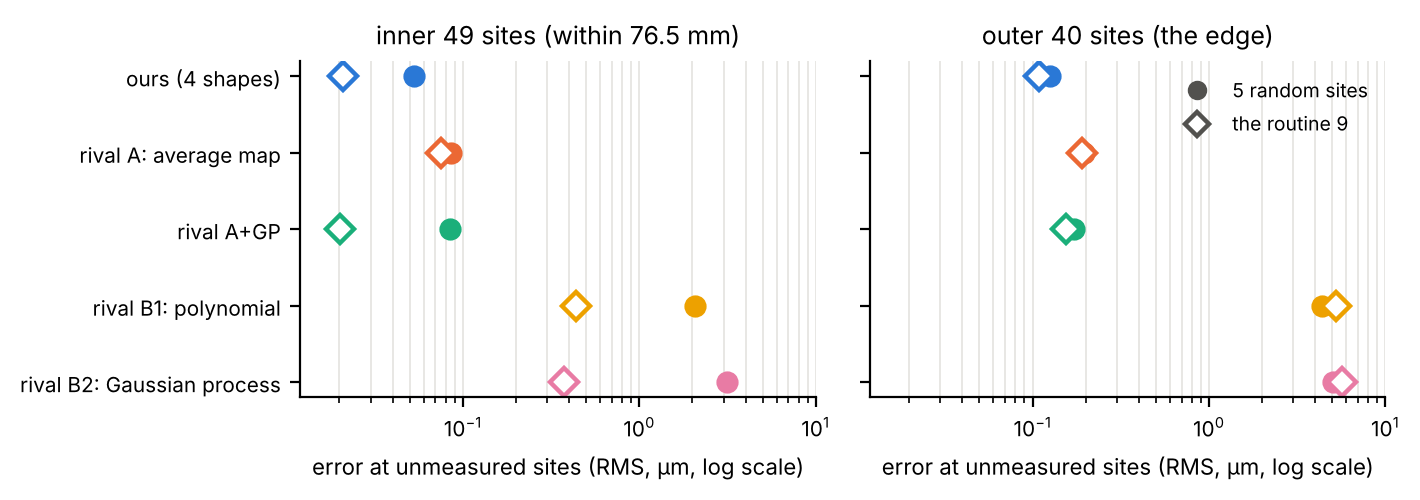

In [18]:
# Figure 1: every method at 5 random sites and with the routine 9 (log scale: the baselines differ by 100x)
COLOURS = {'ours': '#2a78d6', 'rival A': '#eb6834', 'rival A+GP': '#1baf7a',
           'rival B1': '#eda100', 'rival B2': '#e87ba4'}
LABELS = {'ours': 'ours (4 shapes)', 'rival A': 'rival A: average map', 'rival A+GP': 'rival A+GP',
          'rival B1': 'rival B1: polynomial', 'rival B2': 'rival B2: Gaussian process'}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), sharey=True)
for g, ax in enumerate(axes):
    for i, meth in enumerate(METHODS[::-1]):
        ax.plot(rmse(A, 5, meth, 'C', g), i, 'o', ms=7, color=COLOURS[meth])
        ax.plot(rmse(A, 'routine 9', meth, 'C', g), i, 'D', ms=7, mfc='white', mec=COLOURS[meth], mew=1.6)
    ax.set_xscale('log')
    ax.set_xlim(0.012, 10)
    ax.set_yticks(range(len(METHODS)))
    ax.set_yticklabels([LABELS[m] for m in METHODS[::-1]], fontsize=8)
    ax.set_title(['inner 49 sites (within 76.5 mm)', 'outer 40 sites (the edge)'][g], fontsize=9)
    ax.set_xlabel('error at unmeasured sites (RMS, µm, log scale)', fontsize=8)
    ax.grid(axis='x', color='#e4e3df', lw=0.6, which='both')
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=7.5)
axes[1].plot([], [], 'o', color='#52514e', label='5 random sites')
axes[1].plot([], [], 'D', mfc='white', mec='#52514e', mew=1.6, label='the routine 9')
axes[1].legend(fontsize=7, frameon=False, loc='upper right')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'part2_baselines.png'), dpi=220, bbox_inches='tight')
plt.show()

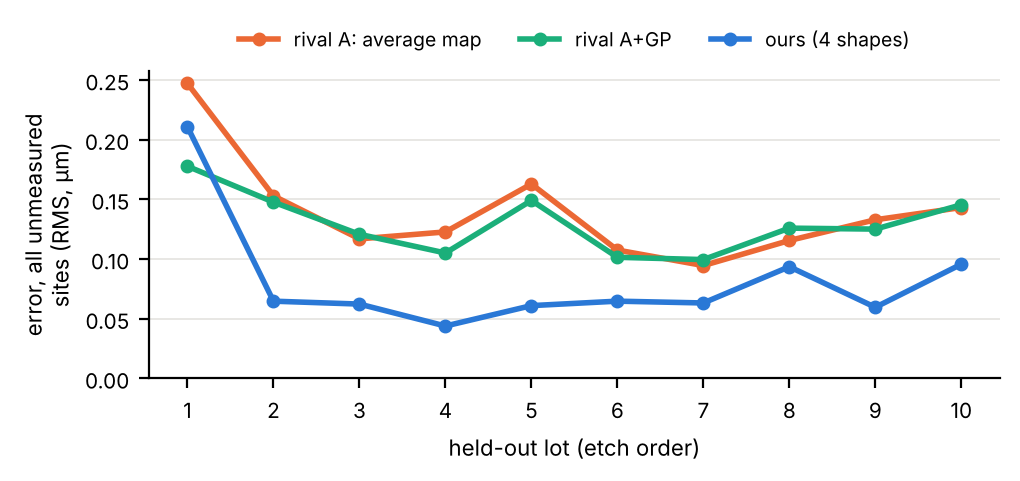

In [19]:
# Figure 2: lot by lot at 5 random sites (score C), the model against the two history-based rivals
fig, ax = plt.subplots(figsize=(5.2, 2.6))
for meth in ['rival A', 'rival A+GP', 'ours']:
    ax.plot(lots, rmse(A, 5, meth, per_lot=True), '-o', lw=2, ms=4, color=COLOURS[meth], label=LABELS[meth])
ax.set_xticks(lots)
ax.set_xlabel('held-out lot (etch order)', fontsize=8)
ax.set_ylabel('error, all unmeasured\nsites (RMS, µm)', fontsize=8)
ax.set_ylim(0, None)
ax.grid(axis='y', color='#e4e3df', lw=0.6)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=7.5)
ax.legend(fontsize=7, frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.2))
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'part2_per_lot.png'), dpi=220, bbox_inches='tight')
plt.show()

## 11. Summary of part 2
- **History is essential.** Methods that use only the new wafer's readings miss the edge by
  microns. The model beats the average-map baseline in every held-out lot, at 5 random sites and
  with the routine 9, on both targets.
- **One bad reading among the inputs needs a check.** Without it the model loses to rival A on the
  all-sites score. With a leave-one-out check it wins every lot, though only narrowly on that score,
  because the two suspect readings can't be predicted when hidden.
- **The edge can be recovered from the routine 9 as actually measured**, once the second instrument's
  offset and scatter are learned from training lots.
- **Learning from earlier lots only** costs about 4% at 5 sites.
- **Position in the lot** helps when few sites are measured (about 10% at 3 sites, 4% at 5).

**Open for part 3:** the check's threshold and the interval width are still set after seeing these
lots; lot 1 (unusual tilt) is where rival A+GP still wins; the inner sites with the routine 9 are a
tie with A+GP; position in the lot is still out of the model; and the sites themselves are still
random or routine, not chosen.